<a href="https://colab.research.google.com/github/kaluarachchiteshan/agromaster-ml/blob/10_test_new_values/notebooks/10_test_new_values.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 10 - Test the final model on new values | Group 41 AgroMaster
# Loads the saved XGBoost model and turns any price history into the same 25 features used in training.
from google.colab import drive
drive.mount('/content/drive')

import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from xgboost import XGBClassifier

OUT_DIR = "/content/drive/MyDrive/agromaster"
KEYS = ["state", "district", "market", "commodity", "variety", "grade"]
PRICES = ["min_price", "max_price", "modal_price"]
CLASS_NAMES = ["Low", "Medium", "High"]

cfg   = json.load(open(os.path.join(OUT_DIR, "feature_config.json")))
EXTRA = json.load(open(os.path.join(OUT_DIR, "extended_features.json")))["extra_features"]
NUM, CAT = cfg["num_features"] + EXTRA, cfg["cat_features"]          # 22 numerical + 3 categorical = 25 features
HORIZON, HIST_DAYS, FFILL_LIMIT, MIN_HIST = cfg["horizon"], cfg["hist_days"], cfg["ffill_limit"], cfg["min_hist"]
SEASONS = {int(k): v for k, v in cfg["seasons"].items()}

model = XGBClassifier(); model.load_model(os.path.join(OUT_DIR, "final_xgboost.json"))
prep  = joblib.load(os.path.join(OUT_DIR, "final_tree_prep.joblib"))      # median imputer + category encoder, fitted on 2001-2023
thr   = pd.read_csv(os.path.join(OUT_DIR, "final_thresholds.csv")).set_index("commodity")
print("Model loaded. Commodities:", list(thr.index))

def build_features(hist, commodity, state):
    """hist: one market's reports with columns date, min_price, max_price, modal_price (INR per quintal).
    Returns one feature row per reported date that has enough history (same rules as notebooks 04 and 07)."""
    g = hist.copy()
    g["date"] = pd.to_datetime(g["date"])
    g = g.groupby("date")[PRICES].median().sort_index()            # one row per date
    cal = pd.date_range(g.index[0], g.index[-1], freq="D")
    raw = g.reindex(cal)                                            # daily calendar; NaN on days with no report
    f = raw.ffill(limit=FFILL_LIMIT)
    m = f["modal_price"]

    out = pd.DataFrame(index=cal)
    out["min_price"], out["max_price"], out["modal_price"] = f["min_price"], f["max_price"], m
    out["price_spread"]   = f["max_price"] - f["min_price"]
    out["spread_ratio"]   = out["price_spread"] / m
    out["modal_lag_1"]    = m.shift(1)
    out["modal_lag_7"]    = m.shift(7)
    out["modal_lag_30"]   = m.shift(30)
    out["ma_7"]           = m.rolling(7,  min_periods=4).mean()
    out["ma_30"]          = m.rolling(30, min_periods=15).mean()
    out["volatility_30"]  = m.rolling(30, min_periods=15).std()
    out["price_momentum"] = m / m.shift(7) - 1
    obs = raw["modal_price"]
    out["hist_mean_90"]   = obs.shift(1).rolling(HIST_DAYS, min_periods=MIN_HIST).mean()   # 90 days strictly before t
    out["current_ratio"]  = obs / out["hist_mean_90"]
    out = out[obs.notna() & out["hist_mean_90"].notna() & out["ma_30"].notna()].astype("float32")

    out["month"] = out.index.month; out["year"] = out.index.year; out["day_of_year"] = out.index.dayofyear
    out["season"] = out["month"].map(SEASONS)
    out["commodity"], out["state"] = commodity, state
    out["rel_mean_90"] = out["current_ratio"]                       # the 7 relative features (notebook 07)
    out["rel_ma_30"]   = out["modal_price"] / out["ma_30"]
    out["rel_ma_7"]    = out["modal_price"] / out["ma_7"]
    out["trend_30_90"] = out["ma_30"] / out["hist_mean_90"]
    out["cv_30"]       = out["volatility_30"] / out["ma_30"]
    out["change_1"]    = out["modal_price"] / out["modal_lag_1"] - 1
    out["change_30"]   = out["modal_price"] / out["modal_lag_30"] - 1
    return out.rename_axis("date")

def predict(feats):
    """Risk class for 7 days ahead, with the probability of each class."""
    X = prep.transform(feats[NUM + CAT]).astype("float32")
    proba = model.predict_proba(X)
    res = pd.DataFrame(proba, columns=[f"p_{c}" for c in CLASS_NAMES], index=feats.index).round(3)
    res.insert(0, "predicted_risk", [CLASS_NAMES[i] for i in proba.argmax(axis=1)])
    res.insert(0, "price_vs_90day_avg", feats["rel_mean_90"].round(3))
    return res

Mounted at /content/drive
Model loaded. Commodities: ['Brinjal', 'Green Chilli', 'Onion', 'Potato', 'Tomato']


In [2]:
# TEST A - Does the saved model reproduce the official test results?
# Rebuilds features from the cleaned data with build_features() for random series and compares with notebook 08.
N_SERIES = 30

clean = pd.read_parquet(os.path.join(OUT_DIR, "agmarknet_clean.parquet"))
clean = clean.sort_values(KEYS + ["date"], kind="stable").reset_index(drop=True)
clean["sid"] = clean.groupby(KEYS, observed=True).ngroup()          # same series id as notebook 04
official = pd.read_parquet(os.path.join(OUT_DIR, "test_predictions.parquet"))

rng = np.random.default_rng(0)
rows = []
for sid in rng.choice(official["sid"].unique(), size=N_SERIES, replace=False):
    s = clean[clean["sid"] == sid]
    feats = build_features(s[["date"] + PRICES], str(s["commodity"].iloc[0]), str(s["state"].iloc[0]))
    rows.append(predict(feats).reset_index().assign(sid=sid))
mine = pd.concat(rows)
both = official.merge(mine, on=["sid", "date"], how="inner")
same = (both["pred_XGBoost"].map(dict(enumerate(CLASS_NAMES))) == both["predicted_risk"])
diff = (both["xgb_proba_High"] - both["p_High"]).abs().max()
print(f"Compared {len(both):,} test-period predictions from {N_SERIES} random series")
print(f"Same risk class as notebook 08: {100 * same.mean():.2f}% | largest difference in P(High): {diff:.4f}")
print("PASS - the saved model and the feature code work as in the report" if same.mean() > 0.999 else "CHECK - predictions differ from notebook 08")

Compared 10,089 test-period predictions from 30 random series
Same risk class as notebook 08: 100.00% | largest difference in P(High): 0.0005
PASS - the saved model and the feature code work as in the report


Tomato | Khed (Chakan), Maharashtra | prediction date 2024-03-19
Price on 2024-03-19: 1300 INR/quintal | 90-day average: 1809
PREDICTED risk for 2024-03-26: Medium  (P Low 0.16, Medium 0.73, High 0.11)
ACTUAL: price 750, ratio 0.415 -> High (High if ratio <= 0.478, Medium if <= 0.724)
Wrong


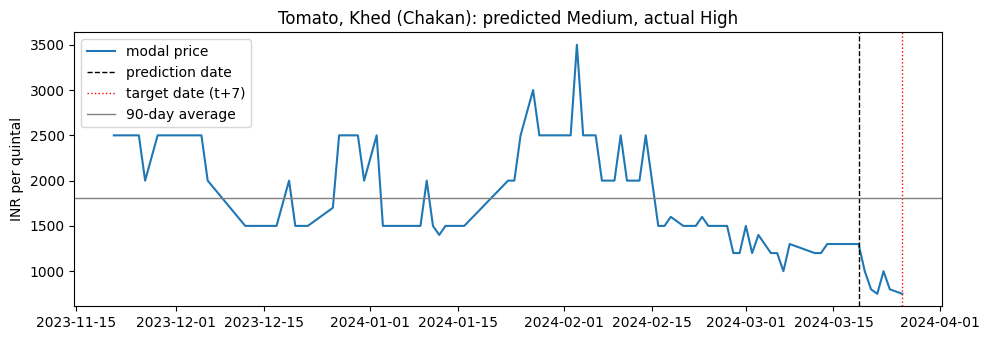

In [3]:
# TEST B - One real market and date from the test period: prediction vs what actually happened
COMMODITY = "Tomato"
DATE = None              # e.g. "2024-05-20"; None = pick a random High-risk day of this commodity
MARKET = None            # e.g. "Kolar"; None = use the market of the picked day

pick = official[(official["commodity"] == COMMODITY)]
pick = pick[pick["date"] == pd.Timestamp(DATE)] if DATE else pick[pick["y_true"] == 2]
if MARKET: pick = pick[pick["market"] == MARKET]
assert len(pick), "No test row for this commodity / market / date - change the settings"
row = pick.sample(1, random_state=1).iloc[0]
s = clean[clean["sid"] == row["sid"]]
feats = build_features(s[["date"] + PRICES], COMMODITY, str(row["state"]))
res = predict(feats.loc[[row["date"]]]).iloc[0]

t = row["date"]; actual_price = s.set_index("date")["modal_price"].get(t + pd.Timedelta(days=HORIZON))
print(f"{COMMODITY} | {row['market']}, {row['state']} | prediction date {t.date()}")
print(f"Price on {t.date()}: {feats.loc[t, 'modal_price']:.0f} INR/quintal | 90-day average: {feats.loc[t, 'hist_mean_90']:.0f}")
print(f"PREDICTED risk for {(t + pd.Timedelta(days=HORIZON)).date()}: {res['predicted_risk']}  "
      f"(P Low {res['p_Low']:.2f}, Medium {res['p_Medium']:.2f}, High {res['p_High']:.2f})")
print(f"ACTUAL: price {actual_price:.0f}, ratio {row['ratio']:.3f} -> {CLASS_NAMES[row['y_true']]} "
      f"(High if ratio <= {thr.loc[COMMODITY, 'p_high']:.3f}, Medium if <= {thr.loc[COMMODITY, 'p_medium']:.3f})")
print("Correct" if res["predicted_risk"] == CLASS_NAMES[row["y_true"]] else "Wrong")

w = s.set_index("date")["modal_price"]
w = w[(w.index >= t - pd.Timedelta(days=120)) & (w.index <= t + pd.Timedelta(days=HORIZON))]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(w.index, w.values, lw=1.5, label="modal price")
ax.axvline(t, color="k", ls="--", lw=1, label="prediction date")
ax.axvline(t + pd.Timedelta(days=HORIZON), color="r", ls=":", lw=1, label="target date (t+7)")
ax.axhline(feats.loc[t, "hist_mean_90"], color="grey", lw=1, label="90-day average")
ax.set_ylabel("INR per quintal")
ax.set_title(f"{COMMODITY}, {row['market']}: predicted {res['predicted_risk']}, actual {CLASS_NAMES[row['y_true']]}")
ax.legend(); plt.tight_layout(); plt.show()

In [4]:
# TEST C - Scenario test: made-up price histories where the correct answer is obvious
STATE = official[official["commodity"] == COMMODITY]["state"].mode()[0]
print("States seen for", COMMODITY, ":", sorted(official.loc[official["commodity"] == COMMODITY, "state"].astype(str).unique()))

def make_history(last_day, base, shape, days=120, seed=0):
    """Daily prices for `days` days ending on last_day. shape changes the last 14 days."""
    r = np.random.default_rng(seed)
    d = pd.date_range(end=last_day, periods=days, freq="D")
    modal = base * (1 + r.normal(0, 0.03, days))                     # normal day-to-day noise
    tail = np.linspace(1, {"stable": 1.0, "already_fallen": 0.45, "rising": 1.4}[shape], 14)
    modal[-14:] *= tail
    return pd.DataFrame({"date": d, "min_price": modal * 0.85, "max_price": modal * 1.15, "modal_price": modal})

base = float(clean.loc[(clean["commodity"] == COMMODITY) & (clean["date"].dt.year == 2025), "modal_price"].median())
expected = {"stable": "Low", "already_fallen": "High", "rising": "Low"}
out = []
for shape, exp in expected.items():
    f = build_features(make_history("2025-06-15", base, shape), COMMODITY, STATE)
    r = predict(f).iloc[-1]
    out.append({"scenario": shape, "price_vs_90day_avg": r["price_vs_90day_avg"], "expected": exp,
                "predicted": r["predicted_risk"], "p_High": r["p_High"],
                "check": "OK" if r["predicted_risk"] == exp else "differs"})
print(f"\n{COMMODITY}, {STATE}, base price {base:.0f} INR/quintal, prediction date 2025-06-15")
print(pd.DataFrame(out).to_string(index=False))

States seen for Tomato : ['Andhra Pradesh', 'Chandigarh', 'Chattisgarh', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'NCT of Delhi', 'Odisha', 'Punjab', 'Rajasthan', 'Uttar Pradesh', 'Uttrakhand', 'West Bengal']

Tomato, Uttar Pradesh, base price 1800 INR/quintal, prediction date 2025-06-15
      scenario  price_vs_90day_avg expected predicted  p_High   check
        stable               1.031      Low       Low   0.001      OK
already_fallen               0.482     High    Medium   0.407 differs
        rising               1.405      Low       Low   0.001      OK


In [5]:
# TEST D - Your own values: fill a CSV with one market's prices and predict
# CSV columns: date (YYYY-MM-DD), min_price, max_price, modal_price  (INR per quintal)
# Give about 100 days or more, ending on the day you want to predict from (the model uses the previous 90 days).
# Missing days are fine; the file needs at least 30 reports in the 90 days before the last date.
MY_FILE = os.path.join(OUT_DIR, "my_prices.csv")
MY_COMMODITY = "Onion"            # one of: Brinjal, Green Chilli, Onion, Potato, Tomato
MY_STATE = "Maharashtra"          # state of the market

if not os.path.exists(MY_FILE):   # first run: write a template from real prices, then edit it in Drive
    cand = official[(official["commodity"] == MY_COMMODITY) & (official["state"].astype(str) == MY_STATE)]
    sid = (cand if len(cand) else official[official["commodity"] == MY_COMMODITY])["sid"].iloc[0]
    ex = clean[clean["sid"] == sid].tail(120)[["date"] + PRICES]
    ex.to_csv(MY_FILE, index=False)
    MY_STATE = str(clean.loc[clean["sid"] == sid, "state"].iloc[0])
    print(f"Template written to {MY_FILE} ({len(ex)} rows from a real {MY_COMMODITY} market in {MY_STATE}). Edit it and run this cell again.")

mine = pd.read_csv(MY_FILE)
f = build_features(mine, MY_COMMODITY, MY_STATE)
assert len(f), "Not enough history: give at least 100 days with at least 30 reports in the last 90 days"
r = predict(f).iloc[-1]
t = f.index[-1]
print(f"{MY_COMMODITY}, {MY_STATE} | last date in file {t.date()} | price {f['modal_price'].iloc[-1]:.0f} | 90-day average {f['hist_mean_90'].iloc[-1]:.0f}")
print(f"Predicted risk for {(t + pd.Timedelta(days=HORIZON)).date()}: {r['predicted_risk']}  "
      f"(P Low {r['p_Low']:.2f}, Medium {r['p_Medium']:.2f}, High {r['p_High']:.2f})")
print("\nLast 10 prediction dates in the file:")
print(predict(f).tail(10).to_string())

Template written to /content/drive/MyDrive/agromaster/my_prices.csv (120 rows from a real Onion market in Maharashtra). Edit it and run this cell again.
Onion, Maharashtra | last date in file 2025-01-26 | price 1250 | 90-day average 2043
Predicted risk for 2025-02-02: High  (P Low 0.13, Medium 0.41, High 0.46)

Last 10 prediction dates in the file:
            price_vs_90day_avg predicted_risk  p_Low  p_Medium  p_High
date                                                                  
2025-01-14               0.677           High  0.010     0.479   0.511
2025-01-15               0.776         Medium  0.019     0.547   0.434
2025-01-16               0.783         Medium  0.025     0.614   0.361
2025-01-18               0.691         Medium  0.025     0.589   0.386
2025-01-19               0.684         Medium  0.021     0.583   0.395
2025-01-20               1.064         Medium  0.155     0.575   0.270
2025-01-21               0.970         Medium  0.239     0.607   0.154
2025-01-22

In [ ]:
# 10 - Test the final model on new values | Group 41 AgroMaster
# Loads the saved XGBoost model and turns any price history into the same 25 features used in training.
from google.colab import drive
drive.mount('/content/drive')

import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from xgboost import XGBClassifier

OUT_DIR = "/content/drive/MyDrive/agromaster"
KEYS = ["state", "district", "market", "commodity", "variety", "grade"]
PRICES = ["min_price", "max_price", "modal_price"]
CLASS_NAMES = ["Low", "Medium", "High"]

cfg   = json.load(open(os.path.join(OUT_DIR, "feature_config.json")))
EXTRA = json.load(open(os.path.join(OUT_DIR, "extended_features.json")))["extra_features"]
NUM, CAT = cfg["num_features"] + EXTRA, cfg["cat_features"]          # 22 numerical + 3 categorical = 25 features
HORIZON, HIST_DAYS, FFILL_LIMIT, MIN_HIST = cfg["horizon"], cfg["hist_days"], cfg["ffill_limit"], cfg["min_hist"]
SEASONS = {int(k): v for k, v in cfg["seasons"].items()}

model = XGBClassifier(); model.load_model(os.path.join(OUT_DIR, "final_xgboost.json"))
prep  = joblib.load(os.path.join(OUT_DIR, "final_tree_prep.joblib"))      # median imputer + category encoder, fitted on 2001-2023
thr   = pd.read_csv(os.path.join(OUT_DIR, "final_thresholds.csv")).set_index("commodity")
print("Model loaded. Commodities:", list(thr.index))

def build_features(hist, commodity, state):
    """hist: one market's reports with columns date, min_price, max_price, modal_price (INR per quintal).
    Returns one feature row per reported date that has enough history (same rules as notebooks 04 and 07)."""
    g = hist.copy()
    g["date"] = pd.to_datetime(g["date"])
    g = g.groupby("date")[PRICES].median().sort_index()            # one row per date
    cal = pd.date_range(g.index[0], g.index[-1], freq="D")
    raw = g.reindex(cal)                                            # daily calendar; NaN on days with no report
    f = raw.ffill(limit=FFILL_LIMIT)
    m = f["modal_price"]

    out = pd.DataFrame(index=cal)
    out["min_price"], out["max_price"], out["modal_price"] = f["min_price"], f["max_price"], m
    out["price_spread"]   = f["max_price"] - f["min_price"]
    out["spread_ratio"]   = out["price_spread"] / m
    out["modal_lag_1"]    = m.shift(1)
    out["modal_lag_7"]    = m.shift(7)
    out["modal_lag_30"]   = m.shift(30)
    out["ma_7"]           = m.rolling(7,  min_periods=4).mean()
    out["ma_30"]          = m.rolling(30, min_periods=15).mean()
    out["volatility_30"]  = m.rolling(30, min_periods=15).std()
    out["price_momentum"] = m / m.shift(7) - 1
    obs = raw["modal_price"]
    out["hist_mean_90"]   = obs.shift(1).rolling(HIST_DAYS, min_periods=MIN_HIST).mean()   # 90 days strictly before t
    out["current_ratio"]  = obs / out["hist_mean_90"]
    out = out[obs.notna() & out["hist_mean_90"].notna() & out["ma_30"].notna()].astype("float32")

    out["month"] = out.index.month; out["year"] = out.index.year; out["day_of_year"] = out.index.dayofyear
    out["season"] = out["month"].map(SEASONS)
    out["commodity"], out["state"] = commodity, state
    out["rel_mean_90"] = out["current_ratio"]                       # the 7 relative features (notebook 07)
    out["rel_ma_30"]   = out["modal_price"] / out["ma_30"]
    out["rel_ma_7"]    = out["modal_price"] / out["ma_7"]
    out["trend_30_90"] = out["ma_30"] / out["hist_mean_90"]
    out["cv_30"]       = out["volatility_30"] / out["ma_30"]
    out["change_1"]    = out["modal_price"] / out["modal_lag_1"] - 1
    out["change_30"]   = out["modal_price"] / out["modal_lag_30"] - 1
    return out.rename_axis("date")

def predict(feats):
    """Risk class for 7 days ahead, with the probability of each class."""
    X = prep.transform(feats[NUM + CAT]).astype("float32")
    proba = model.predict_proba(X)
    res = pd.DataFrame(proba, columns=[f"p_{c}" for c in CLASS_NAMES], index=feats.index).round(3)
    res.insert(0, "predicted_risk", [CLASS_NAMES[i] for i in proba.argmax(axis=1)])
    res.insert(0, "price_vs_90day_avg", feats["rel_mean_90"].round(3))
    return res

Mounted at /content/drive
Model loaded. Commodities: ['Brinjal', 'Green Chilli', 'Onion', 'Potato', 'Tomato']


In [ ]:
# TEST A - Does the saved model reproduce the official test results?
# Rebuilds features from the cleaned data with build_features() for random series and compares with notebook 08.
N_SERIES = 30

clean = pd.read_parquet(os.path.join(OUT_DIR, "agmarknet_clean.parquet"))
clean = clean.sort_values(KEYS + ["date"], kind="stable").reset_index(drop=True)
clean["sid"] = clean.groupby(KEYS, observed=True).ngroup()          # same series id as notebook 04
official = pd.read_parquet(os.path.join(OUT_DIR, "test_predictions.parquet"))

rng = np.random.default_rng(0)
rows = []
for sid in rng.choice(official["sid"].unique(), size=N_SERIES, replace=False):
    s = clean[clean["sid"] == sid]
    feats = build_features(s[["date"] + PRICES], str(s["commodity"].iloc[0]), str(s["state"].iloc[0]))
    rows.append(predict(feats).reset_index().assign(sid=sid))
mine = pd.concat(rows)
both = official.merge(mine, on=["sid", "date"], how="inner")
same = (both["pred_XGBoost"].map(dict(enumerate(CLASS_NAMES))) == both["predicted_risk"])
diff = (both["xgb_proba_High"] - both["p_High"]).abs().max()
print(f"Compared {len(both):,} test-period predictions from {N_SERIES} random series")
print(f"Same risk class as notebook 08: {100 * same.mean():.2f}% | largest difference in P(High): {diff:.4f}")
print("PASS - the saved model and the feature code work as in the report" if same.mean() > 0.999 else "CHECK - predictions differ from notebook 08")

Compared 10,089 test-period predictions from 30 random series
Same risk class as notebook 08: 100.00% | largest difference in P(High): 0.0005
PASS - the saved model and the feature code work as in the report


Tomato | Khed (Chakan), Maharashtra | prediction date 2024-03-19
Price on 2024-03-19: 1300 INR/quintal | 90-day average: 1809
PREDICTED risk for 2024-03-26: Medium  (P Low 0.16, Medium 0.73, High 0.11)
ACTUAL: price 750, ratio 0.415 -> High (High if ratio <= 0.478, Medium if <= 0.724)
Wrong


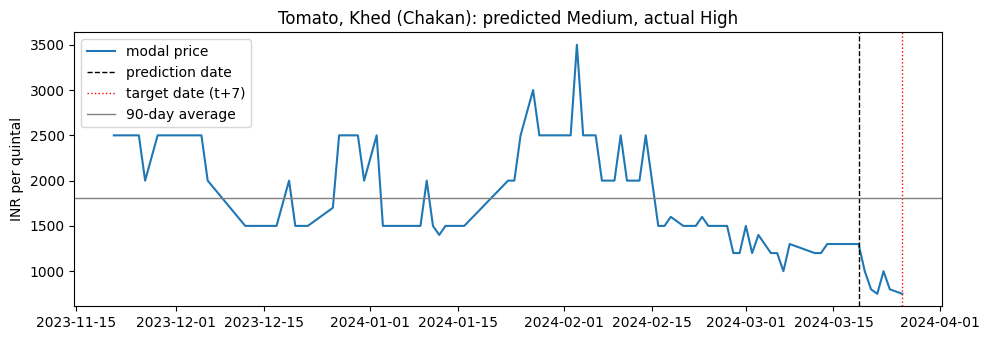

In [ ]:
# TEST B - One real market and date from the test period: prediction vs what actually happened
COMMODITY = "Tomato"
DATE = None              # e.g. "2024-05-20"; None = pick a random High-risk day of this commodity
MARKET = None            # e.g. "Kolar"; None = use the market of the picked day

pick = official[(official["commodity"] == COMMODITY)]
pick = pick[pick["date"] == pd.Timestamp(DATE)] if DATE else pick[pick["y_true"] == 2]
if MARKET: pick = pick[pick["market"] == MARKET]
assert len(pick), "No test row for this commodity / market / date - change the settings"
row = pick.sample(1, random_state=1).iloc[0]
s = clean[clean["sid"] == row["sid"]]
feats = build_features(s[["date"] + PRICES], COMMODITY, str(row["state"]))
res = predict(feats.loc[[row["date"]]]).iloc[0]

t = row["date"]; actual_price = s.set_index("date")["modal_price"].get(t + pd.Timedelta(days=HORIZON))
print(f"{COMMODITY} | {row['market']}, {row['state']} | prediction date {t.date()}")
print(f"Price on {t.date()}: {feats.loc[t, 'modal_price']:.0f} INR/quintal | 90-day average: {feats.loc[t, 'hist_mean_90']:.0f}")
print(f"PREDICTED risk for {(t + pd.Timedelta(days=HORIZON)).date()}: {res['predicted_risk']}  "
      f"(P Low {res['p_Low']:.2f}, Medium {res['p_Medium']:.2f}, High {res['p_High']:.2f})")
print(f"ACTUAL: price {actual_price:.0f}, ratio {row['ratio']:.3f} -> {CLASS_NAMES[row['y_true']]} "
      f"(High if ratio <= {thr.loc[COMMODITY, 'p_high']:.3f}, Medium if <= {thr.loc[COMMODITY, 'p_medium']:.3f})")
print("Correct" if res["predicted_risk"] == CLASS_NAMES[row["y_true"]] else "Wrong")

w = s.set_index("date")["modal_price"]
w = w[(w.index >= t - pd.Timedelta(days=120)) & (w.index <= t + pd.Timedelta(days=HORIZON))]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(w.index, w.values, lw=1.5, label="modal price")
ax.axvline(t, color="k", ls="--", lw=1, label="prediction date")
ax.axvline(t + pd.Timedelta(days=HORIZON), color="r", ls=":", lw=1, label="target date (t+7)")
ax.axhline(feats.loc[t, "hist_mean_90"], color="grey", lw=1, label="90-day average")
ax.set_ylabel("INR per quintal")
ax.set_title(f"{COMMODITY}, {row['market']}: predicted {res['predicted_risk']}, actual {CLASS_NAMES[row['y_true']]}")
ax.legend(); plt.tight_layout(); plt.show()

In [ ]:
# TEST C - Scenario test: made-up price histories where the correct answer is obvious
STATE = official[official["commodity"] == COMMODITY]["state"].mode()[0]
print("States seen for", COMMODITY, ":", sorted(official.loc[official["commodity"] == COMMODITY, "state"].astype(str).unique()))

def make_history(last_day, base, shape, days=120, seed=0):
    """Daily prices for `days` days ending on last_day. shape changes the last 14 days."""
    r = np.random.default_rng(seed)
    d = pd.date_range(end=last_day, periods=days, freq="D")
    modal = base * (1 + r.normal(0, 0.03, days))                     # normal day-to-day noise
    tail = np.linspace(1, {"stable": 1.0, "already_fallen": 0.45, "rising": 1.4}[shape], 14)
    modal[-14:] *= tail
    return pd.DataFrame({"date": d, "min_price": modal * 0.85, "max_price": modal * 1.15, "modal_price": modal})

base = float(clean.loc[(clean["commodity"] == COMMODITY) & (clean["date"].dt.year == 2025), "modal_price"].median())
expected = {"stable": "Low", "already_fallen": "High", "rising": "Low"}
out = []
for shape, exp in expected.items():
    f = build_features(make_history("2025-06-15", base, shape), COMMODITY, STATE)
    r = predict(f).iloc[-1]
    out.append({"scenario": shape, "price_vs_90day_avg": r["price_vs_90day_avg"], "expected": exp,
                "predicted": r["predicted_risk"], "p_High": r["p_High"],
                "check": "OK" if r["predicted_risk"] == exp else "differs"})
print(f"\n{COMMODITY}, {STATE}, base price {base:.0f} INR/quintal, prediction date 2025-06-15")
print(pd.DataFrame(out).to_string(index=False))

States seen for Tomato : ['Andhra Pradesh', 'Chandigarh', 'Chattisgarh', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'NCT of Delhi', 'Odisha', 'Punjab', 'Rajasthan', 'Uttar Pradesh', 'Uttrakhand', 'West Bengal']

Tomato, Uttar Pradesh, base price 1800 INR/quintal, prediction date 2025-06-15
      scenario  price_vs_90day_avg expected predicted  p_High   check
        stable               1.031      Low       Low   0.001      OK
already_fallen               0.482     High    Medium   0.407 differs
        rising               1.405      Low       Low   0.001      OK


In [ ]:
# TEST D - Your own values: fill a CSV with one market's prices and predict
# CSV columns: date (YYYY-MM-DD), min_price, max_price, modal_price  (INR per quintal)
# Give about 100 days or more, ending on the day you want to predict from (the model uses the previous 90 days).
# Missing days are fine; the file needs at least 30 reports in the 90 days before the last date.
MY_FILE = os.path.join(OUT_DIR, "my_prices.csv")
MY_COMMODITY = "Onion"            # one of: Brinjal, Green Chilli, Onion, Potato, Tomato
MY_STATE = "Maharashtra"          # state of the market

if not os.path.exists(MY_FILE):   # first run: write a template from real prices, then edit it in Drive
    cand = official[(official["commodity"] == MY_COMMODITY) & (official["state"].astype(str) == MY_STATE)]
    sid = (cand if len(cand) else official[official["commodity"] == MY_COMMODITY])["sid"].iloc[0]
    ex = clean[clean["sid"] == sid].tail(120)[["date"] + PRICES]
    ex.to_csv(MY_FILE, index=False)
    MY_STATE = str(clean.loc[clean["sid"] == sid, "state"].iloc[0])
    print(f"Template written to {MY_FILE} ({len(ex)} rows from a real {MY_COMMODITY} market in {MY_STATE}). Edit it and run this cell again.")

mine = pd.read_csv(MY_FILE)
f = build_features(mine, MY_COMMODITY, MY_STATE)
assert len(f), "Not enough history: give at least 100 days with at least 30 reports in the last 90 days"
r = predict(f).iloc[-1]
t = f.index[-1]
print(f"{MY_COMMODITY}, {MY_STATE} | last date in file {t.date()} | price {f['modal_price'].iloc[-1]:.0f} | 90-day average {f['hist_mean_90'].iloc[-1]:.0f}")
print(f"Predicted risk for {(t + pd.Timedelta(days=HORIZON)).date()}: {r['predicted_risk']}  "
      f"(P Low {r['p_Low']:.2f}, Medium {r['p_Medium']:.2f}, High {r['p_High']:.2f})")
print("\nLast 10 prediction dates in the file:")
print(predict(f).tail(10).to_string())

Template written to /content/drive/MyDrive/agromaster/my_prices.csv (120 rows from a real Onion market in Maharashtra). Edit it and run this cell again.
Onion, Maharashtra | last date in file 2025-01-26 | price 1250 | 90-day average 2043
Predicted risk for 2025-02-02: High  (P Low 0.13, Medium 0.41, High 0.46)

Last 10 prediction dates in the file:
            price_vs_90day_avg predicted_risk  p_Low  p_Medium  p_High
date                                                                  
2025-01-14               0.677           High  0.010     0.479   0.511
2025-01-15               0.776         Medium  0.019     0.547   0.434
2025-01-16               0.783         Medium  0.025     0.614   0.361
2025-01-18               0.691         Medium  0.025     0.589   0.386
2025-01-19               0.684         Medium  0.021     0.583   0.395
2025-01-20               1.064         Medium  0.155     0.575   0.270
2025-01-21               0.970         Medium  0.239     0.607   0.154
2025-01-22

In [ ]:
# 10 - Test the final model on new values | Group 41 AgroMaster
# Loads the saved XGBoost model and turns any price history into the same 25 features used in training.
from google.colab import drive
drive.mount('/content/drive')

import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from xgboost import XGBClassifier

OUT_DIR = "/content/drive/MyDrive/agromaster"
KEYS = ["state", "district", "market", "commodity", "variety", "grade"]
PRICES = ["min_price", "max_price", "modal_price"]
CLASS_NAMES = ["Low", "Medium", "High"]

cfg   = json.load(open(os.path.join(OUT_DIR, "feature_config.json")))
EXTRA = json.load(open(os.path.join(OUT_DIR, "extended_features.json")))["extra_features"]
NUM, CAT = cfg["num_features"] + EXTRA, cfg["cat_features"]          # 22 numerical + 3 categorical = 25 features
HORIZON, HIST_DAYS, FFILL_LIMIT, MIN_HIST = cfg["horizon"], cfg["hist_days"], cfg["ffill_limit"], cfg["min_hist"]
SEASONS = {int(k): v for k, v in cfg["seasons"].items()}

model = XGBClassifier(); model.load_model(os.path.join(OUT_DIR, "final_xgboost.json"))
prep  = joblib.load(os.path.join(OUT_DIR, "final_tree_prep.joblib"))      # median imputer + category encoder, fitted on 2001-2023
thr   = pd.read_csv(os.path.join(OUT_DIR, "final_thresholds.csv")).set_index("commodity")
print("Model loaded. Commodities:", list(thr.index))

def build_features(hist, commodity, state):
    """hist: one market's reports with columns date, min_price, max_price, modal_price (INR per quintal).
    Returns one feature row per reported date that has enough history (same rules as notebooks 04 and 07)."""
    g = hist.copy()
    g["date"] = pd.to_datetime(g["date"])
    g = g.groupby("date")[PRICES].median().sort_index()            # one row per date
    cal = pd.date_range(g.index[0], g.index[-1], freq="D")
    raw = g.reindex(cal)                                            # daily calendar; NaN on days with no report
    f = raw.ffill(limit=FFILL_LIMIT)
    m = f["modal_price"]

    out = pd.DataFrame(index=cal)
    out["min_price"], out["max_price"], out["modal_price"] = f["min_price"], f["max_price"], m
    out["price_spread"]   = f["max_price"] - f["min_price"]
    out["spread_ratio"]   = out["price_spread"] / m
    out["modal_lag_1"]    = m.shift(1)
    out["modal_lag_7"]    = m.shift(7)
    out["modal_lag_30"]   = m.shift(30)
    out["ma_7"]           = m.rolling(7,  min_periods=4).mean()
    out["ma_30"]          = m.rolling(30, min_periods=15).mean()
    out["volatility_30"]  = m.rolling(30, min_periods=15).std()
    out["price_momentum"] = m / m.shift(7) - 1
    obs = raw["modal_price"]
    out["hist_mean_90"]   = obs.shift(1).rolling(HIST_DAYS, min_periods=MIN_HIST).mean()   # 90 days strictly before t
    out["current_ratio"]  = obs / out["hist_mean_90"]
    out = out[obs.notna() & out["hist_mean_90"].notna() & out["ma_30"].notna()].astype("float32")

    out["month"] = out.index.month; out["year"] = out.index.year; out["day_of_year"] = out.index.dayofyear
    out["season"] = out["month"].map(SEASONS)
    out["commodity"], out["state"] = commodity, state
    out["rel_mean_90"] = out["current_ratio"]                       # the 7 relative features (notebook 07)
    out["rel_ma_30"]   = out["modal_price"] / out["ma_30"]
    out["rel_ma_7"]    = out["modal_price"] / out["ma_7"]
    out["trend_30_90"] = out["ma_30"] / out["hist_mean_90"]
    out["cv_30"]       = out["volatility_30"] / out["ma_30"]
    out["change_1"]    = out["modal_price"] / out["modal_lag_1"] - 1
    out["change_30"]   = out["modal_price"] / out["modal_lag_30"] - 1
    return out.rename_axis("date")

def predict(feats):
    """Risk class for 7 days ahead, with the probability of each class."""
    X = prep.transform(feats[NUM + CAT]).astype("float32")
    proba = model.predict_proba(X)
    res = pd.DataFrame(proba, columns=[f"p_{c}" for c in CLASS_NAMES], index=feats.index).round(3)
    res.insert(0, "predicted_risk", [CLASS_NAMES[i] for i in proba.argmax(axis=1)])
    res.insert(0, "price_vs_90day_avg", feats["rel_mean_90"].round(3))
    return res

Mounted at /content/drive
Model loaded. Commodities: ['Brinjal', 'Green Chilli', 'Onion', 'Potato', 'Tomato']


In [ ]:
# TEST A - Does the saved model reproduce the official test results?
# Rebuilds features from the cleaned data with build_features() for random series and compares with notebook 08.
N_SERIES = 30

clean = pd.read_parquet(os.path.join(OUT_DIR, "agmarknet_clean.parquet"))
clean = clean.sort_values(KEYS + ["date"], kind="stable").reset_index(drop=True)
clean["sid"] = clean.groupby(KEYS, observed=True).ngroup()          # same series id as notebook 04
official = pd.read_parquet(os.path.join(OUT_DIR, "test_predictions.parquet"))

rng = np.random.default_rng(0)
rows = []
for sid in rng.choice(official["sid"].unique(), size=N_SERIES, replace=False):
    s = clean[clean["sid"] == sid]
    feats = build_features(s[["date"] + PRICES], str(s["commodity"].iloc[0]), str(s["state"].iloc[0]))
    rows.append(predict(feats).reset_index().assign(sid=sid))
mine = pd.concat(rows)
both = official.merge(mine, on=["sid", "date"], how="inner")
same = (both["pred_XGBoost"].map(dict(enumerate(CLASS_NAMES))) == both["predicted_risk"])
diff = (both["xgb_proba_High"] - both["p_High"]).abs().max()
print(f"Compared {len(both):,} test-period predictions from {N_SERIES} random series")
print(f"Same risk class as notebook 08: {100 * same.mean():.2f}% | largest difference in P(High): {diff:.4f}")
print("PASS - the saved model and the feature code work as in the report" if same.mean() > 0.999 else "CHECK - predictions differ from notebook 08")

Compared 10,089 test-period predictions from 30 random series
Same risk class as notebook 08: 100.00% | largest difference in P(High): 0.0005
PASS - the saved model and the feature code work as in the report


Tomato | Khed (Chakan), Maharashtra | prediction date 2024-03-19
Price on 2024-03-19: 1300 INR/quintal | 90-day average: 1809
PREDICTED risk for 2024-03-26: Medium  (P Low 0.16, Medium 0.73, High 0.11)
ACTUAL: price 750, ratio 0.415 -> High (High if ratio <= 0.478, Medium if <= 0.724)
Wrong


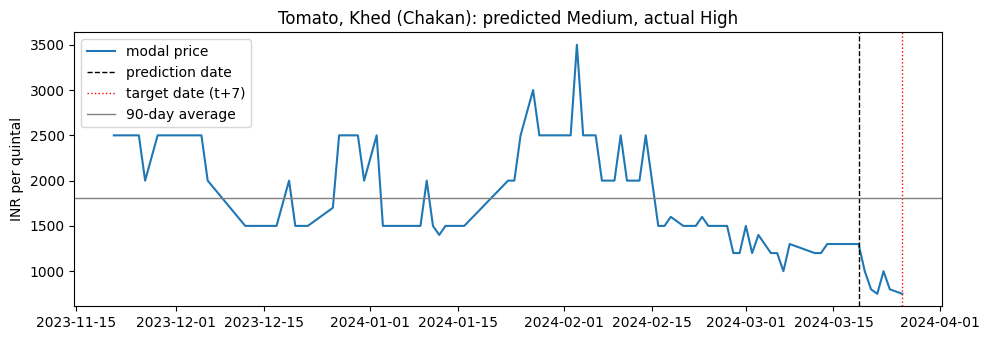

In [ ]:
# TEST B - One real market and date from the test period: prediction vs what actually happened
COMMODITY = "Tomato"
DATE = None              # e.g. "2024-05-20"; None = pick a random High-risk day of this commodity
MARKET = None            # e.g. "Kolar"; None = use the market of the picked day

pick = official[(official["commodity"] == COMMODITY)]
pick = pick[pick["date"] == pd.Timestamp(DATE)] if DATE else pick[pick["y_true"] == 2]
if MARKET: pick = pick[pick["market"] == MARKET]
assert len(pick), "No test row for this commodity / market / date - change the settings"
row = pick.sample(1, random_state=1).iloc[0]
s = clean[clean["sid"] == row["sid"]]
feats = build_features(s[["date"] + PRICES], COMMODITY, str(row["state"]))
res = predict(feats.loc[[row["date"]]]).iloc[0]

t = row["date"]; actual_price = s.set_index("date")["modal_price"].get(t + pd.Timedelta(days=HORIZON))
print(f"{COMMODITY} | {row['market']}, {row['state']} | prediction date {t.date()}")
print(f"Price on {t.date()}: {feats.loc[t, 'modal_price']:.0f} INR/quintal | 90-day average: {feats.loc[t, 'hist_mean_90']:.0f}")
print(f"PREDICTED risk for {(t + pd.Timedelta(days=HORIZON)).date()}: {res['predicted_risk']}  "
      f"(P Low {res['p_Low']:.2f}, Medium {res['p_Medium']:.2f}, High {res['p_High']:.2f})")
print(f"ACTUAL: price {actual_price:.0f}, ratio {row['ratio']:.3f} -> {CLASS_NAMES[row['y_true']]} "
      f"(High if ratio <= {thr.loc[COMMODITY, 'p_high']:.3f}, Medium if <= {thr.loc[COMMODITY, 'p_medium']:.3f})")
print("Correct" if res["predicted_risk"] == CLASS_NAMES[row["y_true"]] else "Wrong")

w = s.set_index("date")["modal_price"]
w = w[(w.index >= t - pd.Timedelta(days=120)) & (w.index <= t + pd.Timedelta(days=HORIZON))]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(w.index, w.values, lw=1.5, label="modal price")
ax.axvline(t, color="k", ls="--", lw=1, label="prediction date")
ax.axvline(t + pd.Timedelta(days=HORIZON), color="r", ls=":", lw=1, label="target date (t+7)")
ax.axhline(feats.loc[t, "hist_mean_90"], color="grey", lw=1, label="90-day average")
ax.set_ylabel("INR per quintal")
ax.set_title(f"{COMMODITY}, {row['market']}: predicted {res['predicted_risk']}, actual {CLASS_NAMES[row['y_true']]}")
ax.legend(); plt.tight_layout(); plt.show()

In [ ]:
# TEST C - Scenario test: made-up price histories where the correct answer is obvious
STATE = official[official["commodity"] == COMMODITY]["state"].mode()[0]
print("States seen for", COMMODITY, ":", sorted(official.loc[official["commodity"] == COMMODITY, "state"].astype(str).unique()))

def make_history(last_day, base, shape, days=120, seed=0):
    """Daily prices for `days` days ending on last_day. shape changes the last 14 days."""
    r = np.random.default_rng(seed)
    d = pd.date_range(end=last_day, periods=days, freq="D")
    modal = base * (1 + r.normal(0, 0.03, days))                     # normal day-to-day noise
    tail = np.linspace(1, {"stable": 1.0, "already_fallen": 0.45, "rising": 1.4}[shape], 14)
    modal[-14:] *= tail
    return pd.DataFrame({"date": d, "min_price": modal * 0.85, "max_price": modal * 1.15, "modal_price": modal})

base = float(clean.loc[(clean["commodity"] == COMMODITY) & (clean["date"].dt.year == 2025), "modal_price"].median())
expected = {"stable": "Low", "already_fallen": "High", "rising": "Low"}
out = []
for shape, exp in expected.items():
    f = build_features(make_history("2025-06-15", base, shape), COMMODITY, STATE)
    r = predict(f).iloc[-1]
    out.append({"scenario": shape, "price_vs_90day_avg": r["price_vs_90day_avg"], "expected": exp,
                "predicted": r["predicted_risk"], "p_High": r["p_High"],
                "check": "OK" if r["predicted_risk"] == exp else "differs"})
print(f"\n{COMMODITY}, {STATE}, base price {base:.0f} INR/quintal, prediction date 2025-06-15")
print(pd.DataFrame(out).to_string(index=False))

States seen for Tomato : ['Andhra Pradesh', 'Chandigarh', 'Chattisgarh', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'NCT of Delhi', 'Odisha', 'Punjab', 'Rajasthan', 'Uttar Pradesh', 'Uttrakhand', 'West Bengal']

Tomato, Uttar Pradesh, base price 1800 INR/quintal, prediction date 2025-06-15
      scenario  price_vs_90day_avg expected predicted  p_High   check
        stable               1.031      Low       Low   0.001      OK
already_fallen               0.482     High    Medium   0.407 differs
        rising               1.405      Low       Low   0.001      OK


In [ ]:
# TEST D - Your own values: fill a CSV with one market's prices and predict
# CSV columns: date (YYYY-MM-DD), min_price, max_price, modal_price  (INR per quintal)
# Give about 100 days or more, ending on the day you want to predict from (the model uses the previous 90 days).
# Missing days are fine; the file needs at least 30 reports in the 90 days before the last date.
MY_FILE = os.path.join(OUT_DIR, "my_prices.csv")
MY_COMMODITY = "Onion"            # one of: Brinjal, Green Chilli, Onion, Potato, Tomato
MY_STATE = "Maharashtra"          # state of the market

if not os.path.exists(MY_FILE):   # first run: write a template from real prices, then edit it in Drive
    cand = official[(official["commodity"] == MY_COMMODITY) & (official["state"].astype(str) == MY_STATE)]
    sid = (cand if len(cand) else official[official["commodity"] == MY_COMMODITY])["sid"].iloc[0]
    ex = clean[clean["sid"] == sid].tail(120)[["date"] + PRICES]
    ex.to_csv(MY_FILE, index=False)
    MY_STATE = str(clean.loc[clean["sid"] == sid, "state"].iloc[0])
    print(f"Template written to {MY_FILE} ({len(ex)} rows from a real {MY_COMMODITY} market in {MY_STATE}). Edit it and run this cell again.")

mine = pd.read_csv(MY_FILE)
f = build_features(mine, MY_COMMODITY, MY_STATE)
assert len(f), "Not enough history: give at least 100 days with at least 30 reports in the last 90 days"
r = predict(f).iloc[-1]
t = f.index[-1]
print(f"{MY_COMMODITY}, {MY_STATE} | last date in file {t.date()} | price {f['modal_price'].iloc[-1]:.0f} | 90-day average {f['hist_mean_90'].iloc[-1]:.0f}")
print(f"Predicted risk for {(t + pd.Timedelta(days=HORIZON)).date()}: {r['predicted_risk']}  "
      f"(P Low {r['p_Low']:.2f}, Medium {r['p_Medium']:.2f}, High {r['p_High']:.2f})")
print("\nLast 10 prediction dates in the file:")
print(predict(f).tail(10).to_string())

Template written to /content/drive/MyDrive/agromaster/my_prices.csv (120 rows from a real Onion market in Maharashtra). Edit it and run this cell again.
Onion, Maharashtra | last date in file 2025-01-26 | price 1250 | 90-day average 2043
Predicted risk for 2025-02-02: High  (P Low 0.13, Medium 0.41, High 0.46)

Last 10 prediction dates in the file:
            price_vs_90day_avg predicted_risk  p_Low  p_Medium  p_High
date                                                                  
2025-01-14               0.677           High  0.010     0.479   0.511
2025-01-15               0.776         Medium  0.019     0.547   0.434
2025-01-16               0.783         Medium  0.025     0.614   0.361
2025-01-18               0.691         Medium  0.025     0.589   0.386
2025-01-19               0.684         Medium  0.021     0.583   0.395
2025-01-20               1.064         Medium  0.155     0.575   0.270
2025-01-21               0.970         Medium  0.239     0.607   0.154
2025-01-22

In [ ]:
# 10 - Test the final model on new values | Group 41 AgroMaster
# Loads the saved XGBoost model and turns any price history into the same 25 features used in training.
from google.colab import drive
drive.mount('/content/drive')

import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from xgboost import XGBClassifier

OUT_DIR = "/content/drive/MyDrive/agromaster"
KEYS = ["state", "district", "market", "commodity", "variety", "grade"]
PRICES = ["min_price", "max_price", "modal_price"]
CLASS_NAMES = ["Low", "Medium", "High"]

cfg   = json.load(open(os.path.join(OUT_DIR, "feature_config.json")))
EXTRA = json.load(open(os.path.join(OUT_DIR, "extended_features.json")))["extra_features"]
NUM, CAT = cfg["num_features"] + EXTRA, cfg["cat_features"]          # 22 numerical + 3 categorical = 25 features
HORIZON, HIST_DAYS, FFILL_LIMIT, MIN_HIST = cfg["horizon"], cfg["hist_days"], cfg["ffill_limit"], cfg["min_hist"]
SEASONS = {int(k): v for k, v in cfg["seasons"].items()}

model = XGBClassifier(); model.load_model(os.path.join(OUT_DIR, "final_xgboost.json"))
prep  = joblib.load(os.path.join(OUT_DIR, "final_tree_prep.joblib"))      # median imputer + category encoder, fitted on 2001-2023
thr   = pd.read_csv(os.path.join(OUT_DIR, "final_thresholds.csv")).set_index("commodity")
print("Model loaded. Commodities:", list(thr.index))

def build_features(hist, commodity, state):
    """hist: one market's reports with columns date, min_price, max_price, modal_price (INR per quintal).
    Returns one feature row per reported date that has enough history (same rules as notebooks 04 and 07)."""
    g = hist.copy()
    g["date"] = pd.to_datetime(g["date"])
    g = g.groupby("date")[PRICES].median().sort_index()            # one row per date
    cal = pd.date_range(g.index[0], g.index[-1], freq="D")
    raw = g.reindex(cal)                                            # daily calendar; NaN on days with no report
    f = raw.ffill(limit=FFILL_LIMIT)
    m = f["modal_price"]

    out = pd.DataFrame(index=cal)
    out["min_price"], out["max_price"], out["modal_price"] = f["min_price"], f["max_price"], m
    out["price_spread"]   = f["max_price"] - f["min_price"]
    out["spread_ratio"]   = out["price_spread"] / m
    out["modal_lag_1"]    = m.shift(1)
    out["modal_lag_7"]    = m.shift(7)
    out["modal_lag_30"]   = m.shift(30)
    out["ma_7"]           = m.rolling(7,  min_periods=4).mean()
    out["ma_30"]          = m.rolling(30, min_periods=15).mean()
    out["volatility_30"]  = m.rolling(30, min_periods=15).std()
    out["price_momentum"] = m / m.shift(7) - 1
    obs = raw["modal_price"]
    out["hist_mean_90"]   = obs.shift(1).rolling(HIST_DAYS, min_periods=MIN_HIST).mean()   # 90 days strictly before t
    out["current_ratio"]  = obs / out["hist_mean_90"]
    out = out[obs.notna() & out["hist_mean_90"].notna() & out["ma_30"].notna()].astype("float32")

    out["month"] = out.index.month; out["year"] = out.index.year; out["day_of_year"] = out.index.dayofyear
    out["season"] = out["month"].map(SEASONS)
    out["commodity"], out["state"] = commodity, state
    out["rel_mean_90"] = out["current_ratio"]                       # the 7 relative features (notebook 07)
    out["rel_ma_30"]   = out["modal_price"] / out["ma_30"]
    out["rel_ma_7"]    = out["modal_price"] / out["ma_7"]
    out["trend_30_90"] = out["ma_30"] / out["hist_mean_90"]
    out["cv_30"]       = out["volatility_30"] / out["ma_30"]
    out["change_1"]    = out["modal_price"] / out["modal_lag_1"] - 1
    out["change_30"]   = out["modal_price"] / out["modal_lag_30"] - 1
    return out.rename_axis("date")

def predict(feats):
    """Risk class for 7 days ahead, with the probability of each class."""
    X = prep.transform(feats[NUM + CAT]).astype("float32")
    proba = model.predict_proba(X)
    res = pd.DataFrame(proba, columns=[f"p_{c}" for c in CLASS_NAMES], index=feats.index).round(3)
    res.insert(0, "predicted_risk", [CLASS_NAMES[i] for i in proba.argmax(axis=1)])
    res.insert(0, "price_vs_90day_avg", feats["rel_mean_90"].round(3))
    return res

Mounted at /content/drive
Model loaded. Commodities: ['Brinjal', 'Green Chilli', 'Onion', 'Potato', 'Tomato']


In [ ]:
# TEST A - Does the saved model reproduce the official test results?
# Rebuilds features from the cleaned data with build_features() for random series and compares with notebook 08.
N_SERIES = 30

clean = pd.read_parquet(os.path.join(OUT_DIR, "agmarknet_clean.parquet"))
clean = clean.sort_values(KEYS + ["date"], kind="stable").reset_index(drop=True)
clean["sid"] = clean.groupby(KEYS, observed=True).ngroup()          # same series id as notebook 04
official = pd.read_parquet(os.path.join(OUT_DIR, "test_predictions.parquet"))

rng = np.random.default_rng(0)
rows = []
for sid in rng.choice(official["sid"].unique(), size=N_SERIES, replace=False):
    s = clean[clean["sid"] == sid]
    feats = build_features(s[["date"] + PRICES], str(s["commodity"].iloc[0]), str(s["state"].iloc[0]))
    rows.append(predict(feats).reset_index().assign(sid=sid))
mine = pd.concat(rows)
both = official.merge(mine, on=["sid", "date"], how="inner")
same = (both["pred_XGBoost"].map(dict(enumerate(CLASS_NAMES))) == both["predicted_risk"])
diff = (both["xgb_proba_High"] - both["p_High"]).abs().max()
print(f"Compared {len(both):,} test-period predictions from {N_SERIES} random series")
print(f"Same risk class as notebook 08: {100 * same.mean():.2f}% | largest difference in P(High): {diff:.4f}")
print("PASS - the saved model and the feature code work as in the report" if same.mean() > 0.999 else "CHECK - predictions differ from notebook 08")

Compared 10,089 test-period predictions from 30 random series
Same risk class as notebook 08: 100.00% | largest difference in P(High): 0.0005
PASS - the saved model and the feature code work as in the report


Tomato | Khed (Chakan), Maharashtra | prediction date 2024-03-19
Price on 2024-03-19: 1300 INR/quintal | 90-day average: 1809
PREDICTED risk for 2024-03-26: Medium  (P Low 0.16, Medium 0.73, High 0.11)
ACTUAL: price 750, ratio 0.415 -> High (High if ratio <= 0.478, Medium if <= 0.724)
Wrong


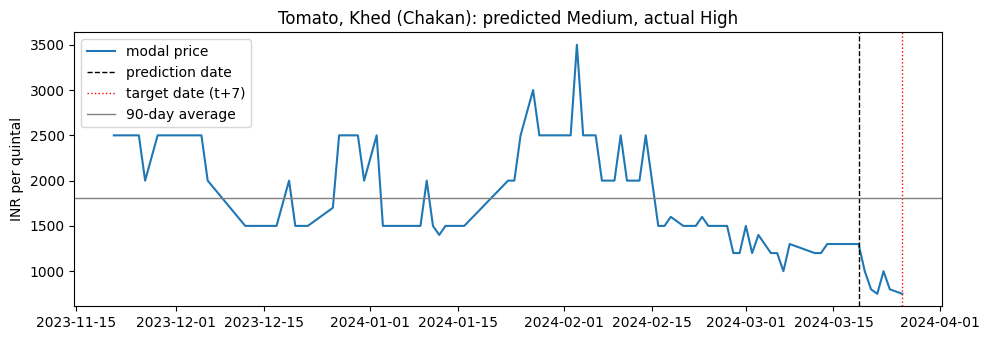

In [ ]:
# TEST B - One real market and date from the test period: prediction vs what actually happened
COMMODITY = "Tomato"
DATE = None              # e.g. "2024-05-20"; None = pick a random High-risk day of this commodity
MARKET = None            # e.g. "Kolar"; None = use the market of the picked day

pick = official[(official["commodity"] == COMMODITY)]
pick = pick[pick["date"] == pd.Timestamp(DATE)] if DATE else pick[pick["y_true"] == 2]
if MARKET: pick = pick[pick["market"] == MARKET]
assert len(pick), "No test row for this commodity / market / date - change the settings"
row = pick.sample(1, random_state=1).iloc[0]
s = clean[clean["sid"] == row["sid"]]
feats = build_features(s[["date"] + PRICES], COMMODITY, str(row["state"]))
res = predict(feats.loc[[row["date"]]]).iloc[0]

t = row["date"]; actual_price = s.set_index("date")["modal_price"].get(t + pd.Timedelta(days=HORIZON))
print(f"{COMMODITY} | {row['market']}, {row['state']} | prediction date {t.date()}")
print(f"Price on {t.date()}: {feats.loc[t, 'modal_price']:.0f} INR/quintal | 90-day average: {feats.loc[t, 'hist_mean_90']:.0f}")
print(f"PREDICTED risk for {(t + pd.Timedelta(days=HORIZON)).date()}: {res['predicted_risk']}  "
      f"(P Low {res['p_Low']:.2f}, Medium {res['p_Medium']:.2f}, High {res['p_High']:.2f})")
print(f"ACTUAL: price {actual_price:.0f}, ratio {row['ratio']:.3f} -> {CLASS_NAMES[row['y_true']]} "
      f"(High if ratio <= {thr.loc[COMMODITY, 'p_high']:.3f}, Medium if <= {thr.loc[COMMODITY, 'p_medium']:.3f})")
print("Correct" if res["predicted_risk"] == CLASS_NAMES[row["y_true"]] else "Wrong")

w = s.set_index("date")["modal_price"]
w = w[(w.index >= t - pd.Timedelta(days=120)) & (w.index <= t + pd.Timedelta(days=HORIZON))]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(w.index, w.values, lw=1.5, label="modal price")
ax.axvline(t, color="k", ls="--", lw=1, label="prediction date")
ax.axvline(t + pd.Timedelta(days=HORIZON), color="r", ls=":", lw=1, label="target date (t+7)")
ax.axhline(feats.loc[t, "hist_mean_90"], color="grey", lw=1, label="90-day average")
ax.set_ylabel("INR per quintal")
ax.set_title(f"{COMMODITY}, {row['market']}: predicted {res['predicted_risk']}, actual {CLASS_NAMES[row['y_true']]}")
ax.legend(); plt.tight_layout(); plt.show()

In [ ]:
# TEST C - Scenario test: made-up price histories where the correct answer is obvious
STATE = official[official["commodity"] == COMMODITY]["state"].mode()[0]
print("States seen for", COMMODITY, ":", sorted(official.loc[official["commodity"] == COMMODITY, "state"].astype(str).unique()))

def make_history(last_day, base, shape, days=120, seed=0):
    """Daily prices for `days` days ending on last_day. shape changes the last 14 days."""
    r = np.random.default_rng(seed)
    d = pd.date_range(end=last_day, periods=days, freq="D")
    modal = base * (1 + r.normal(0, 0.03, days))                     # normal day-to-day noise
    tail = np.linspace(1, {"stable": 1.0, "already_fallen": 0.45, "rising": 1.4}[shape], 14)
    modal[-14:] *= tail
    return pd.DataFrame({"date": d, "min_price": modal * 0.85, "max_price": modal * 1.15, "modal_price": modal})

base = float(clean.loc[(clean["commodity"] == COMMODITY) & (clean["date"].dt.year == 2025), "modal_price"].median())
expected = {"stable": "Low", "already_fallen": "High", "rising": "Low"}
out = []
for shape, exp in expected.items():
    f = build_features(make_history("2025-06-15", base, shape), COMMODITY, STATE)
    r = predict(f).iloc[-1]
    out.append({"scenario": shape, "price_vs_90day_avg": r["price_vs_90day_avg"], "expected": exp,
                "predicted": r["predicted_risk"], "p_High": r["p_High"],
                "check": "OK" if r["predicted_risk"] == exp else "differs"})
print(f"\n{COMMODITY}, {STATE}, base price {base:.0f} INR/quintal, prediction date 2025-06-15")
print(pd.DataFrame(out).to_string(index=False))

States seen for Tomato : ['Andhra Pradesh', 'Chandigarh', 'Chattisgarh', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'NCT of Delhi', 'Odisha', 'Punjab', 'Rajasthan', 'Uttar Pradesh', 'Uttrakhand', 'West Bengal']

Tomato, Uttar Pradesh, base price 1800 INR/quintal, prediction date 2025-06-15
      scenario  price_vs_90day_avg expected predicted  p_High   check
        stable               1.031      Low       Low   0.001      OK
already_fallen               0.482     High    Medium   0.407 differs
        rising               1.405      Low       Low   0.001      OK


In [ ]:
# TEST D - Your own values: fill a CSV with one market's prices and predict
# CSV columns: date (YYYY-MM-DD), min_price, max_price, modal_price  (INR per quintal)
# Give about 100 days or more, ending on the day you want to predict from (the model uses the previous 90 days).
# Missing days are fine; the file needs at least 30 reports in the 90 days before the last date.
MY_FILE = os.path.join(OUT_DIR, "my_prices.csv")
MY_COMMODITY = "Onion"            # one of: Brinjal, Green Chilli, Onion, Potato, Tomato
MY_STATE = "Maharashtra"          # state of the market

if not os.path.exists(MY_FILE):   # first run: write a template from real prices, then edit it in Drive
    cand = official[(official["commodity"] == MY_COMMODITY) & (official["state"].astype(str) == MY_STATE)]
    sid = (cand if len(cand) else official[official["commodity"] == MY_COMMODITY])["sid"].iloc[0]
    ex = clean[clean["sid"] == sid].tail(120)[["date"] + PRICES]
    ex.to_csv(MY_FILE, index=False)
    MY_STATE = str(clean.loc[clean["sid"] == sid, "state"].iloc[0])
    print(f"Template written to {MY_FILE} ({len(ex)} rows from a real {MY_COMMODITY} market in {MY_STATE}). Edit it and run this cell again.")

mine = pd.read_csv(MY_FILE)
f = build_features(mine, MY_COMMODITY, MY_STATE)
assert len(f), "Not enough history: give at least 100 days with at least 30 reports in the last 90 days"
r = predict(f).iloc[-1]
t = f.index[-1]
print(f"{MY_COMMODITY}, {MY_STATE} | last date in file {t.date()} | price {f['modal_price'].iloc[-1]:.0f} | 90-day average {f['hist_mean_90'].iloc[-1]:.0f}")
print(f"Predicted risk for {(t + pd.Timedelta(days=HORIZON)).date()}: {r['predicted_risk']}  "
      f"(P Low {r['p_Low']:.2f}, Medium {r['p_Medium']:.2f}, High {r['p_High']:.2f})")
print("\nLast 10 prediction dates in the file:")
print(predict(f).tail(10).to_string())

Template written to /content/drive/MyDrive/agromaster/my_prices.csv (120 rows from a real Onion market in Maharashtra). Edit it and run this cell again.
Onion, Maharashtra | last date in file 2025-01-26 | price 1250 | 90-day average 2043
Predicted risk for 2025-02-02: High  (P Low 0.13, Medium 0.41, High 0.46)

Last 10 prediction dates in the file:
            price_vs_90day_avg predicted_risk  p_Low  p_Medium  p_High
date                                                                  
2025-01-14               0.677           High  0.010     0.479   0.511
2025-01-15               0.776         Medium  0.019     0.547   0.434
2025-01-16               0.783         Medium  0.025     0.614   0.361
2025-01-18               0.691         Medium  0.025     0.589   0.386
2025-01-19               0.684         Medium  0.021     0.583   0.395
2025-01-20               1.064         Medium  0.155     0.575   0.270
2025-01-21               0.970         Medium  0.239     0.607   0.154
2025-01-22